In [2]:
import pandas as pd
import numpy as np
import catboost as cb
import os

# Проверка, видит ли библиотека мою видеокарту
print(f"CatBoost version: {cb.__version__}")
print(f"Доступно GPU для обучения: {cb.utils.get_gpu_device_count()}")

CatBoost version: 1.2.8


AttributeError: module 'catboost' has no attribute 'utils'

In [3]:
import catboost
from catboost import CatBoostClassifier, Pool
import catboost.utils as cb_utils # Импортируем утилиты напрямую

print(f"CatBoost version: {catboost.__version__}")

# Пробуем вызвать проверку GPU через прямой импорт
try:
    gpu_count = cb_utils.get_gpu_device_count()
    print(f"✅ Доступно GPU для обучения: {gpu_count}")
except Exception as e:
    print(f"❌ Ошибка при проверке GPU: {e}")

CatBoost version: 1.2.8
✅ Доступно GPU для обучения: 1


In [14]:
import pandas as pd
import numpy as np
import os

def load_flight_data(n_rows=1000000):
    print("🚀 Начинаю загрузку данных...")
    
    # Исправленные названия колонок (согласно спецификации оригинального датасета)
    cols = [
        'MONTH', 'DAY', 'DAY_OF_WEEK', 'AIRLINE', 
        'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', # Исправлено здесь
        'SCHEDULED_DEPARTURE', 'DISTANCE', 'ARRIVAL_DELAY'
    ]
    
    # 3. Загружаем основной массив
    try:
        df = pd.read_csv('data/flights.csv', 
            usecols=cols,
            nrows=n_rows,
            low_memory=False
        )
    except ValueError as e:
        print(f"*** ❌ Ошибка в названиях колонок: {e}")
        return None, None, None

    # Переименуем для удобства, чтобы код дальше не ломался
    df = df.rename(columns={'DESTINATION_AIRPORT': 'DEST_AIRPORT'})
    
    # 4. Очистка
    df = df.dropna(subset=['ARRIVAL_DELAY'])
    
    # 5. Target
    df['target'] = (df['ARRIVAL_DELAY'] > 15).astype(np.int8)
    
    # 6. Оптимизация памяти
    for col in df.select_dtypes(include=['int64']).columns:
        df[col] = pd.to_numeric(df[col], downcast='integer')
    for col in df.select_dtypes(include=['float64']).columns:
        df[col] = pd.to_numeric(df[col], downcast='float')
    
    # 7. Категории
    for col in ['AIRLINE', 'ORIGIN_AIRPORT', 'DEST_AIRPORT']:
        df[col] = df[col].astype('category')
            
    print(f"✅ Успешно! RAM: {df.memory_usage().sum() / 1024**2:.2f} MB")
    return df

# Загружаем
df = load_flight_data(n_rows=1000000)
if df is not None:
    display(df.head())

🚀 Начинаю загрузку данных...
✅ Успешно! RAM: 22.85 MB


,MONTH,DAY,DAY_OF_WEEK,AIRLINE,ORIGIN_AIRPORT,DEST_AIRPORT,SCHEDULED_DEPARTURE,DISTANCE,ARRIVAL_DELAY,target
0,1,1,4,AS,ANC,SEA,5,1448,-22.0,0
1,1,1,4,AA,LAX,PBI,10,2330,-9.0,0
2,1,1,4,US,SFO,CLT,20,2296,5.0,0
3,1,1,4,AA,LAX,MIA,20,2342,-9.0,0
4,1,1,4,AS,SEA,ANC,25,1448,-21.0,0


In [15]:
def feature_engineering(df):
    print("🛠️ Начинаю генерацию признаков...")
    
    # 1. Извлекаем ЧАС вылета
    # SCHEDULED_DEPARTURE — это HHMM (например, 1023 -> 10 часов)
    df['DEP_HOUR'] = (df['SCHEDULED_DEPARTURE'] // 100).astype(np.int8)
    
    # 2. Удаляем ненужные и "опасные" колонки
    # ARRIVAL_DELAY удаляем обязательно, иначе модель "подсмотрит" ответ (Data Leakage)
    # SCHEDULED_DEPARTURE больше не нужен, у нас есть DEP_HOUR
    cols_to_drop = ['SCHEDULED_DEPARTURE', 'ARRIVAL_DELAY']
    df_final = df.drop(columns=cols_to_drop)
    
    print("✅ Новые признаки созданы!")
    return df_final

df_ready = feature_engineering(df)
display(df_ready.head())

🛠️ Начинаю генерацию признаков...
✅ Новые признаки созданы!


,MONTH,DAY,DAY_OF_WEEK,AIRLINE,ORIGIN_AIRPORT,DEST_AIRPORT,DISTANCE,target,DEP_HOUR
0,1,1,4,AS,ANC,SEA,1448,0,0
1,1,1,4,AA,LAX,PBI,2330,0,0
2,1,1,4,US,SFO,CLT,2296,0,0
3,1,1,4,AA,LAX,MIA,2342,0,0
4,1,1,4,AS,SEA,ANC,1448,0,0


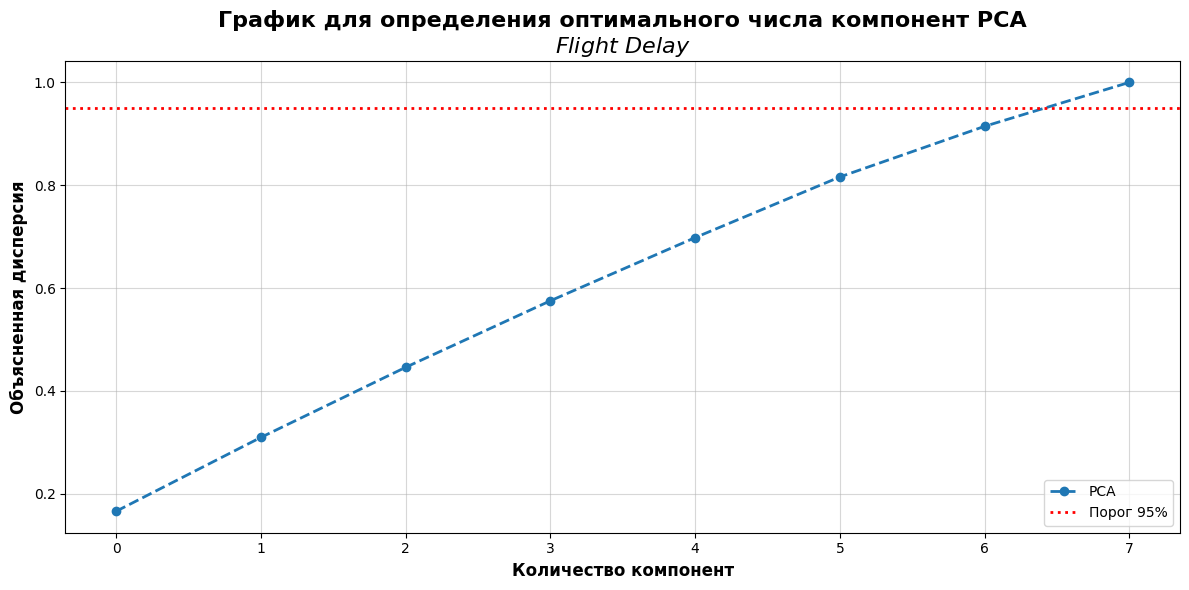

Объясненная дисперсия каждой компонентой: [0.16586189 0.14363722 0.13629478 0.12941811 0.12282304 0.11803643
 0.09845844 0.08547009]


In [29]:
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# 1. Кодируем категории в числа для PCA
df_pca = df_ready.copy()
le = LabelEncoder()
for col in ['AIRLINE', 'ORIGIN_AIRPORT', 'DEST_AIRPORT']:
    df_pca[col] = le.fit_transform(df_pca[col].astype(str))

# 2. Выделяем признаки (X) и целевую переменную (y)
X = df_pca.drop('target', axis=1)
y = df_pca['target']

# 3. Стандартизация
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Применяем PCA
# Сначала запустим PCA без ограничения, чтобы увидеть "дисперсию"
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# Визуализация объясненной дисперсии
plt.figure(figsize=(12, 6))
plt.plot(np.cumsum(pca.explained_variance_ratio_), marker='o', linestyle='--', label='PCA', linewidth=2)
plt.xlabel('Количество компонент', size=12, weight='bold')
plt.ylabel('Объясненная дисперсия', size=12, weight='bold')
plt.title('График для определения оптимального числа компонент PCA\n$Flight$ $Delay$', size=16, weight='bold')
plt.axhline(y=0.95, color='r', linestyle=':', label='Порог 95%', linewidth=2)
plt.grid(alpha=0.5)
plt.tight_layout()
plt.legend()
plt.savefig('notebooks/PCA_optimum.jpg', dpi=300)

plt.show()
plt.close

print(f"Объясненная дисперсия каждой компонентой: {pca.explained_variance_ratio_}")


In [30]:
# Выбираем 7 компонент, так как на графике это дает > 90%
pca_final = PCA(n_components=7)
X_pca_final = pca_final.fit_transform(X_scaled)

from sklearn.model_selection import train_test_split

# Разбиваем на Train/Test со стратификацией
# Это гарантирует, что и в Train, и в Test будет, например, ровно 19% задержек

# 1. Для данных с PCA
X_train_pca, X_test_pca, y_train, y_test = train_test_split(
    X_pca_final, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y  # <--- ВОТ ОНО, САМОЕ ВАЖНОЕ
)

# 2. Для исходных данных (Raw)
# Используем те же индексы (через random_state)
X_train_raw, X_test_raw, _, _ = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

print(f"Доля задержек в исходных данных: {y.mean():.2%}")
print(f"Доля задержек в обучающей выборке: {y_train.mean():.2%}")
print(f"Доля задержек в тестовой выборке: {y_test.mean():.2%}")

Доля задержек в исходных данных: 22.27%
Доля задержек в обучающей выборке: 22.27%
Доля задержек в тестовой выборке: 22.27%


In [31]:
import time
import os
import pandas as pd
import catboost as cb
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

def train_and_eval(X_train, X_test, y_train, y_test, name="Model", is_raw=False):
    """
    Функция для обучения модели CatBoost и оценки её качества.
    """
    print(f"\n*** Запуск обучения: {name}...")
    
    # Фиксируем время начала обучения
    start_time = time.time()
    
    # 1. Инициализация модели CatBoostClassifier с параметрами
    model = cb.CatBoostClassifier(
        iterations=1000,           # Максимальное количество деревьев (итераций)
        learning_rate=0.1,         # Скорость обучения (шаг градиентного спуска)
        depth=6,                   # Глубина деревьев (по гуглу оптимально для начала 6-10)
        task_type="GPU",           # Использование дискретной видеокарты
        devices='0',               # Индекс используемого GPU
        auto_class_weights='Balanced', # Авто-балансировка классов (важно при 22% задержек)
        verbose=100,               # Выводить логи обучения каждые 100 шагов
        early_stopping_rounds=50,  # Остановка, если качество не растет 50 итераций подряд
        random_seed=42             # Фиксация случайности для воспроизводимости результатов
    )
    
    # 2. Определение категориальных признаков, удобство CatBoost
    # Если мы обучаем "сырую" модель, передаем список текстовых колонок
    cat_features = ['AIRLINE', 'ORIGIN_AIRPORT', 'DEST_AIRPORT'] if is_raw else None
    
    # 3. Обучаем модель
    model.fit(
        X_train, y_train,
        eval_set=(X_test, y_test), # Валидация на тестовых данных в процессе обучения
        cat_features=cat_features, # Подключаем категории (только для Raw данных)
        use_best_model=True        # Сохранить версию модели с лучшим результатом на тесте
    )
    
    # 4. Расчет времени обучения и получение предсказаний
    exec_time = time.time() - start_time
    preds = model.predict(X_test)             # Классы (0 или 1)
    probs = model.predict_proba(X_test)[:, 1] # Вероятности для расчета ROC-AUC
    
    # 5. Сбор метрик качества в словарь
    metrics = {
        "Модель": name,
        "Accuracy": round(accuracy_score(y_test, preds), 4),   # Общая точность
        "Precision": round(precision_score(y_test, preds), 4), # Точность прогноза задержек
        "Recall": round(recall_score(y_test, preds), 4),       # Полнота охвата реальных задержек
        "F1-Score": round(f1_score(y_test, preds), 4),         # Баланс между Precision и Recall
        "ROC-AUC": round(roc_auc_score(y_test, probs), 4),     # Качество ранжирования вероятностей
        "Время (сек)": round(exec_time, 2)                      # Время работы GPU
    }
    
    return metrics, model

# --- ЗАПУСК ЭКСПЕРИМЕНТОВ ---

# Обучаем модель на данных после PCA (7 компонент)
metrics_pca, model_pca = train_and_eval(X_train_pca, X_test_pca, y_train, y_test, name="CatBoost + PCA")

# Обучаем модель на исходных данных (Raw)
metrics_raw, model_raw = train_and_eval(X_train_raw, X_test_raw, y_train, y_test, name="CatBoost (Raw)", is_raw=True)

# 6. Формирование итоговой сравнительной таблицы
comparison_df = pd.DataFrame([metrics_pca, metrics_raw])

# 7. Подготовка вывода в формате Markdown для отчета
md_table = comparison_df.to_markdown(index=False)

print("\n### Итоговые результаты сравнения:")
print(md_table)

# 8. Сохранение результатов в текстовый файл для документации проекта
with open("notebooks/model_comparison_results.txt", "w", encoding="utf-8") as f:
    f.write("# Результаты сравнения моделей предсказания задержек авиарейсов\n\n")
    f.write("Данные: 1 000 000 строк. Балансировка классов: Включена.\n\n")
    f.write(md_table)
    f.write(f"\n\nДата и время эксперимента: {pd.Timestamp.now()}")
    f.write("\nКонфигурация системы: RTX 4050 GPU, i7-13620H.")

print("\n✅ Файл 'model_comparison_results.txt' успешно создан в папке проекта ../notebooks/.")


*** Запуск обучения: CatBoost + PCA...
0:	learn: 0.6878252	test: 0.6878381	best: 0.6878381 (0)	total: 152ms	remaining: 2m 31s
100:	learn: 0.6399212	test: 0.6416740	best: 0.6416740 (100)	total: 1.67s	remaining: 14.8s
200:	learn: 0.6316726	test: 0.6347400	best: 0.6347400 (200)	total: 3.29s	remaining: 13.1s
300:	learn: 0.6264227	test: 0.6305601	best: 0.6305601 (300)	total: 5.07s	remaining: 11.8s
400:	learn: 0.6226255	test: 0.6278278	best: 0.6278278 (400)	total: 6.63s	remaining: 9.91s
500:	learn: 0.6195126	test: 0.6256867	best: 0.6256867 (500)	total: 8.26s	remaining: 8.23s
600:	learn: 0.6169109	test: 0.6240689	best: 0.6240689 (600)	total: 9.85s	remaining: 6.54s
700:	learn: 0.6145446	test: 0.6227368	best: 0.6227368 (700)	total: 11.5s	remaining: 4.9s
800:	learn: 0.6123210	test: 0.6215147	best: 0.6215147 (800)	total: 13s	remaining: 3.23s
900:	learn: 0.6102921	test: 0.6204907	best: 0.6204907 (900)	total: 14.4s	remaining: 1.59s
999:	learn: 0.6084457	test: 0.6196935	best: 0.6196935 (999)	total:

In [32]:
# Вывести список всех колонок
print("Список колонок:")
print(df.columns.tolist())

# Посмотреть типы данных и наличие пропусков
print("\nИнфо о данных:")
print(df.info())

# Посмотреть пример первых нескольких строк
print("\nПервые 3 строки:")
display(df.head(3))

Список колонок:
['MONTH', 'DAY', 'DAY_OF_WEEK', 'AIRLINE', 'ORIGIN_AIRPORT', 'DEST_AIRPORT', 'SCHEDULED_DEPARTURE', 'DISTANCE', 'ARRIVAL_DELAY', 'target', 'DEP_HOUR']

Инфо о данных:
<class 'pandas.core.frame.DataFrame'>
Index: 957394 entries, 0 to 999999
Data columns (total 11 columns):
 #   Column               Non-Null Count   Dtype   
---  ------               --------------   -----   
 0   MONTH                957394 non-null  int8    
 1   DAY                  957394 non-null  int8    
 2   DAY_OF_WEEK          957394 non-null  int8    
 3   AIRLINE              957394 non-null  category
 4   ORIGIN_AIRPORT       957394 non-null  category
 5   DEST_AIRPORT         957394 non-null  category
 6   SCHEDULED_DEPARTURE  957394 non-null  int16   
 7   DISTANCE             957394 non-null  int16   
 8   ARRIVAL_DELAY        957394 non-null  float32 
 9   target               957394 non-null  int8    
 10  DEP_HOUR             957394 non-null  int8    
dtypes: category(3), float32(1), in

,MONTH,DAY,DAY_OF_WEEK,AIRLINE,ORIGIN_AIRPORT,DEST_AIRPORT,SCHEDULED_DEPARTURE,DISTANCE,ARRIVAL_DELAY,target,DEP_HOUR
0,1,1,4,AS,ANC,SEA,5,1448,-22.0,0,0
1,1,1,4,AA,LAX,PBI,10,2330,-9.0,0,0
2,1,1,4,US,SFO,CLT,20,2296,5.0,0,0
